 Interactive PyBullet Environment with Object Semantics



## 1. Install PyBullet

In [ ]:
!pip -q install pybullet

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.5/80.5 MB 12.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done


## 2. Imports and folders

In [ ]:
import os, math, json, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pybullet as p
import pybullet_data

BASE_DIR = "/content/rsp_task1_pybullet"
URDF_DIR = os.path.join(BASE_DIR, "urdf")
OUTPUT_DIR = os.path.join(BASE_DIR, "outputs")
os.makedirs(URDF_DIR, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

print("URDF_DIR:", URDF_DIR)
print("OUTPUT_DIR:", OUTPUT_DIR)

URDF_DIR: /content/rsp_task1_pybullet/urdf
OUTPUT_DIR: /content/rsp_task1_pybullet/outputs


## 3. Create custom URDF models

The notebook creates:
1. Barrier — obstacle
2. Target zone — inspection target
3. Landmark — reference object
4. Restricted zone — safety zone
5. Two-wheel robot — mobile inspection platform

In [ ]:
def save_text(name, text):
    path = os.path.join(URDF_DIR, name)
    with open(path, "w") as f:
        f.write(text)
    print("Created:", path)

save_text("barrier.urdf", """<?xml version="1.0"?>
<robot name="barrier">
  <link name="base">
    <visual><geometry><box size="1.4 0.18 0.55"/></geometry>
      <material name="blue"><color rgba="0.1 0.25 0.85 1"/></material></visual>
    <collision><geometry><box size="1.4 0.18 0.55"/></geometry></collision>
    <inertial><mass value="1"/><inertia ixx="0.1" ixy="0" ixz="0" iyy="0.1" iyz="0" izz="0.1"/></inertial>
  </link>
</robot>""")

save_text("target_zone.urdf", """<?xml version="1.0"?>
<robot name="target_zone">
  <link name="base">
    <visual><geometry><cylinder radius="0.32" length="0.10"/></geometry>
      <material name="red"><color rgba="0.9 0.05 0.05 1"/></material></visual>
    <collision><geometry><cylinder radius="0.32" length="0.10"/></geometry></collision>
    <inertial><mass value="0.5"/><inertia ixx="0.02" ixy="0" ixz="0" iyy="0.02" iyz="0" izz="0.02"/></inertial>
  </link>
</robot>""")

save_text("landmark.urdf", """<?xml version="1.0"?>
<robot name="landmark">
  <link name="base">
    <visual><geometry><box size="0.45 0.45 0.95"/></geometry>
      <material name="green"><color rgba="0.1 0.75 0.2 1"/></material></visual>
    <collision><geometry><box size="0.45 0.45 0.95"/></geometry></collision>
    <inertial><mass value="0.6"/><inertia ixx="0.03" ixy="0" ixz="0" iyy="0.03" iyz="0" izz="0.03"/></inertial>
  </link>
</robot>""")

save_text("restricted_zone.urdf", """<?xml version="1.0"?>
<robot name="restricted_zone">
  <link name="base">
    <visual><geometry><box size="0.9 0.9 0.05"/></geometry>
      <material name="orange"><color rgba="1.0 0.45 0.0 0.9"/></material></visual>
    <collision><geometry><box size="0.9 0.9 0.05"/></geometry></collision>
    <inertial><mass value="0.1"/><inertia ixx="0.005" ixy="0" ixz="0" iyy="0.005" iyz="0" izz="0.005"/></inertial>
  </link>
</robot>""")

save_text("two_wheel_robot.urdf", """<?xml version="1.0"?>
<robot name="two_wheel_robot">
  <link name="base_link">
    <visual><geometry><box size="0.55 0.38 0.16"/></geometry>
      <material name="body"><color rgba="0.12 0.12 0.12 1"/></material></visual>
    <collision><geometry><box size="0.55 0.38 0.16"/></geometry></collision>
    <inertial><mass value="2"/><inertia ixx="0.05" ixy="0" ixz="0" iyy="0.05" iyz="0" izz="0.08"/></inertial>
  </link>
  <link name="left_wheel">
    <visual><origin rpy="1.5708 0 0"/><geometry><cylinder radius="0.10" length="0.05"/></geometry></visual>
    <collision><origin rpy="1.5708 0 0"/><geometry><cylinder radius="0.10" length="0.05"/></geometry></collision>
    <inertial><mass value="0.2"/><inertia ixx="0.002" ixy="0" ixz="0" iyy="0.002" iyz="0" izz="0.002"/></inertial>
  </link>
  <joint name="left_wheel_joint" type="continuous">
    <parent link="base_link"/><child link="left_wheel"/><origin xyz="0 0.215 -0.06"/><axis xyz="0 1 0"/>
  </joint>
  <link name="right_wheel">
    <visual><origin rpy="1.5708 0 0"/><geometry><cylinder radius="0.10" length="0.05"/></geometry></visual>
    <collision><origin rpy="1.5708 0 0"/><geometry><cylinder radius="0.10" length="0.05"/></geometry></collision>
    <inertial><mass value="0.2"/><inertia ixx="0.002" ixy="0" ixz="0" iyy="0.002" iyz="0" izz="0.002"/></inertial>
  </link>
  <joint name="right_wheel_joint" type="continuous">
    <parent link="base_link"/><child link="right_wheel"/><origin xyz="0 -0.215 -0.06"/><axis xyz="0 1 0"/>
  </joint>
  <link name="caster">
    <visual><geometry><sphere radius="0.055"/></geometry></visual>
    <collision><geometry><sphere radius="0.055"/></geometry></collision>
    <inertial><mass value="0.05"/><inertia ixx="0.001" ixy="0" ixz="0" iyy="0.001" iyz="0" izz="0.001"/></inertial>
  </link>
  <joint name="caster_joint" type="fixed">
    <parent link="base_link"/><child link="caster"/><origin xyz="-0.20 0 -0.09"/>
  </joint>
</robot>""")

Created: /content/rsp_task1_pybullet/urdf/barrier.urdf
Created: /content/rsp_task1_pybullet/urdf/target_zone.urdf
Created: /content/rsp_task1_pybullet/urdf/landmark.urdf
Created: /content/rsp_task1_pybullet/urdf/restricted_zone.urdf
Created: /content/rsp_task1_pybullet/urdf/two_wheel_robot.urdf


## 4. Start PyBullet in DIRECT mode

In [ ]:
if p.isConnected():
    p.disconnect()

cid = p.connect(p.DIRECT)
p.setAdditionalSearchPath(pybullet_data.getDataPath())
p.setGravity(0, 0, -9.81)
plane_id = p.loadURDF("plane.urdf")
print("Connected:", cid)

Connected: 0


## 5. Build the semantic warehouse/inspection scene

In [ ]:
scene_specs = [
    {"name":"Barrier_A","category":"obstacle","urdf":"barrier.urdf","pos":(-1.7,0.2,0.275),"yaw":0},
    {"name":"Barrier_B","category":"obstacle","urdf":"barrier.urdf","pos":(1.2,-1.5,0.275),"yaw":math.pi/2},
    {"name":"Target_A","category":"target","urdf":"target_zone.urdf","pos":(1.9,1.3,0.05),"yaw":0},
    {"name":"Target_B","category":"target","urdf":"target_zone.urdf","pos":(-1.4,-1.8,0.05),"yaw":0},
    {"name":"Landmark_A","category":"landmark","urdf":"landmark.urdf","pos":(-2.0,1.8,0.475),"yaw":0},
    {"name":"Landmark_B","category":"landmark","urdf":"landmark.urdf","pos":(2.1,-0.2,0.475),"yaw":0},
    {"name":"Restricted_A","category":"restricted_zone","urdf":"restricted_zone.urdf","pos":(0.0,1.9,0.025),"yaw":0},
    {"name":"Restricted_B","category":"restricted_zone","urdf":"restricted_zone.urdf","pos":(0.2,-1.9,0.025),"yaw":0},
]

semantic_map = {}
static_positions = {}

for spec in scene_specs:
    body_id = p.loadURDF(
        os.path.join(URDF_DIR, spec["urdf"]),
        basePosition=spec["pos"],
        baseOrientation=p.getQuaternionFromEuler([0,0,spec["yaw"]]),
        useFixedBase=True
    )
    semantic_map[body_id] = {
        "name":spec["name"],
        "category":spec["category"],
        "role":spec["category"]
    }
    static_positions[body_id] = np.array(spec["pos"], dtype=float)

robot_id = p.loadURDF(
    os.path.join(URDF_DIR, "two_wheel_robot.urdf"),
    basePosition=(-0.2,-0.2,0.16),
    baseOrientation=p.getQuaternionFromEuler([0,0,0]),
    useFixedBase=False
)
semantic_map[robot_id] = {
    "name":"Inspector_Robot",
    "category":"robot",
    "role":"mobile_inspection_platform"
}

print("Static objects:", len(scene_specs))
print("Semantic entities including robot:", len(semantic_map))

Static objects: 8
Semantic entities including robot: 9


## 6. Semantic metadata table

In [ ]:
rows = []
for body_id, meta in semantic_map.items():
    pos, _ = p.getBasePositionAndOrientation(body_id)
    rows.append({
        "body_id": body_id,
        "name": meta["name"],
        "category": meta["category"],
        "role": meta["role"],
        "x": round(pos[0],3),
        "y": round(pos[1],3),
        "z": round(pos[2],3)
    })

semantic_df = pd.DataFrame(rows).sort_values(["category","name"]).reset_index(drop=True)
display(semantic_df)

,body_id,name,category,role,x,y,z
0,5,Landmark_A,landmark,landmark,-2.0,1.8,0.475
1,6,Landmark_B,landmark,landmark,2.1,-0.2,0.475
2,1,Barrier_A,obstacle,obstacle,-1.7,0.2,0.275
3,2,Barrier_B,obstacle,obstacle,1.2,-1.5,0.275
4,7,Restricted_A,restricted_zone,restricted_zone,0.0,1.9,0.025
5,8,Restricted_B,restricted_zone,restricted_zone,0.2,-1.9,0.025
6,9,Inspector_Robot,robot,mobile_inspection_platform,-0.2,-0.2,0.160
7,3,Target_A,target,target,1.9,1.3,0.050
8,4,Target_B,target,target,-1.4,-1.8,0.050


## 7. Semantic query mechanism

In [ ]:
def objects_by_category(category):
    out = []
    for body_id, meta in semantic_map.items():
        if meta["category"] == category:
            pos, _ = p.getBasePositionAndOrientation(body_id)
            out.append({
                "body_id": body_id,
                "name": meta["name"],
                "position": tuple(round(v,3) for v in pos)
            })
    return out

def nearest_object(category):
    robot_pos, _ = p.getBasePositionAndOrientation(robot_id)
    robot_xy = np.array(robot_pos[:2])
    candidates = []
    for body_id, meta in semantic_map.items():
        if meta["category"] == category:
            pos, _ = p.getBasePositionAndOrientation(body_id)
            d = np.linalg.norm(np.array(pos[:2]) - robot_xy)
            candidates.append((d, body_id, meta["name"], pos))
    if not candidates:
        return None
    d, body_id, name, pos = min(candidates, key=lambda x: x[0])
    return {
        "body_id":body_id,
        "name":name,
        "category":category,
        "distance_m":round(float(d),3),
        "position":tuple(round(v,3) for v in pos)
    }

print("Targets:", json.dumps(objects_by_category("target"), indent=2))
print("\nNearest target:", json.dumps(nearest_object("target"), indent=2))
print("\nNearest obstacle:", json.dumps(nearest_object("obstacle"), indent=2))

Targets: [
  {
    "body_id": 3,
    "name": "Target_A",
    "position": [
      1.9,
      1.3,
      0.05
    ]
  },
  {
    "body_id": 4,
    "name": "Target_B",
    "position": [
      -1.4,
      -1.8,
      0.05
    ]
  }
]

Nearest target: {
  "body_id": 4,
  "name": "Target_B",
  "category": "target",
  "distance_m": 2.0,
  "position": [
    -1.4,
    -1.8,
    0.05
  ]
}

Nearest obstacle: {
  "body_id": 1,
  "name": "Barrier_A",
  "category": "obstacle",
  "distance_m": 1.552,
  "position": [
    -1.7,
    0.2,
    0.275
  ]
}


## 8. Category highlighting interaction

In [ ]:
def highlight_category(category, rgba):
    names = []
    for body_id, meta in semantic_map.items():
        if meta["category"] == category:
            p.changeVisualShape(body_id, -1, rgbaColor=rgba)
            names.append(meta["name"])
    return names

print("Highlighted:", highlight_category("target", [1,1,0,1]))

Highlighted: ['Target_A', 'Target_B']


## 9. Camera rendering helper

In [ ]:
def render_camera(eye, target=(0,0,0.35), width=640, height=480):
    view = p.computeViewMatrix(eye, target, [0,0,1])
    proj = p.computeProjectionMatrixFOV(60, width/height, 0.1, 20)
    _, _, rgba, _, _ = p.getCameraImage(
        width, height,
        viewMatrix=view,
        projectionMatrix=proj,
        renderer=p.ER_TINY_RENDERER
    )
    rgba = np.array(rgba, dtype=np.uint8).reshape(height, width, 4)
    return rgba[:,:,:3]

def show_save(img, title, filename):
    path = os.path.join(OUTPUT_DIR, filename)
    plt.figure(figsize=(9,6))
    plt.imshow(img)
    plt.title(title)
    plt.axis("off")
    plt.tight_layout()
    plt.savefig(path, dpi=160, bbox_inches="tight")
    plt.show()
    print("Saved:", path)
    return path

## 10. Camera View 1 — robot at Position A

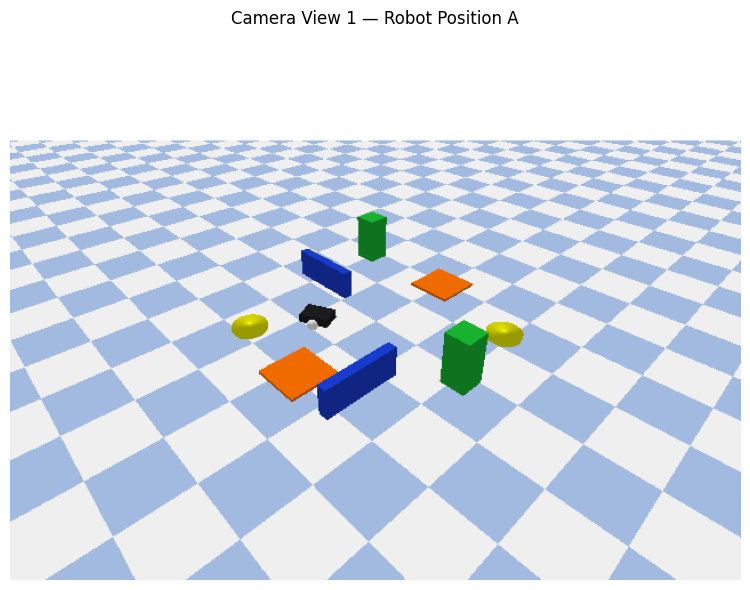

Saved: /content/rsp_task1_pybullet/outputs/camera_view_1.png


'/content/rsp_task1_pybullet/outputs/camera_view_1.png'

In [ ]:
pose_A = (-0.7,-0.8,0.16)
p.resetBasePositionAndOrientation(robot_id, pose_A, p.getQuaternionFromEuler([0,0,math.radians(25)]))
img1 = render_camera((5.2,-5.0,5.0))
show_save(img1, "Camera View 1 — Robot Position A", "camera_view_1.png")

## 11. Camera View 2 — robot at Position B

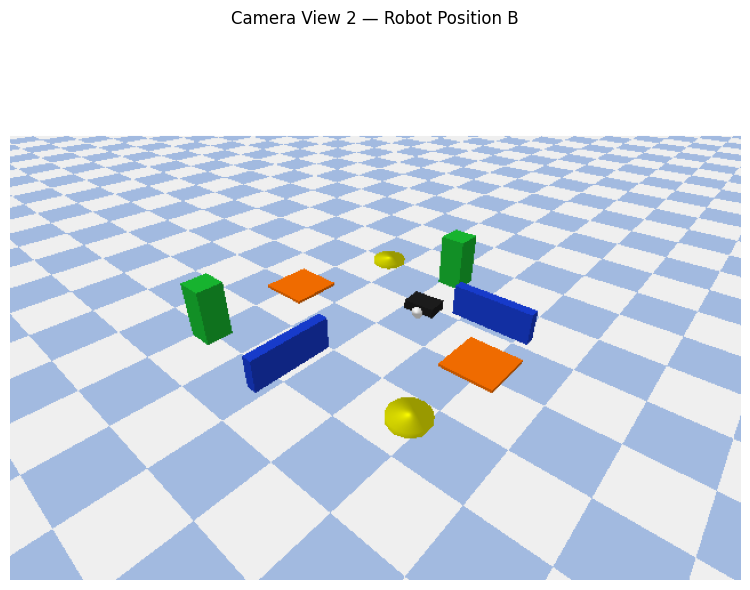

Saved: /content/rsp_task1_pybullet/outputs/camera_view_2.png


'/content/rsp_task1_pybullet/outputs/camera_view_2.png'

In [ ]:
pose_B = (0.8,-0.4,0.16)
p.resetBasePositionAndOrientation(robot_id, pose_B, p.getQuaternionFromEuler([0,0,math.radians(95)]))
img2 = render_camera((-5.0,-4.4,4.5))
show_save(img2, "Camera View 2 — Robot Position B", "camera_view_2.png")

## 12. Camera View 3 — robot at Position C

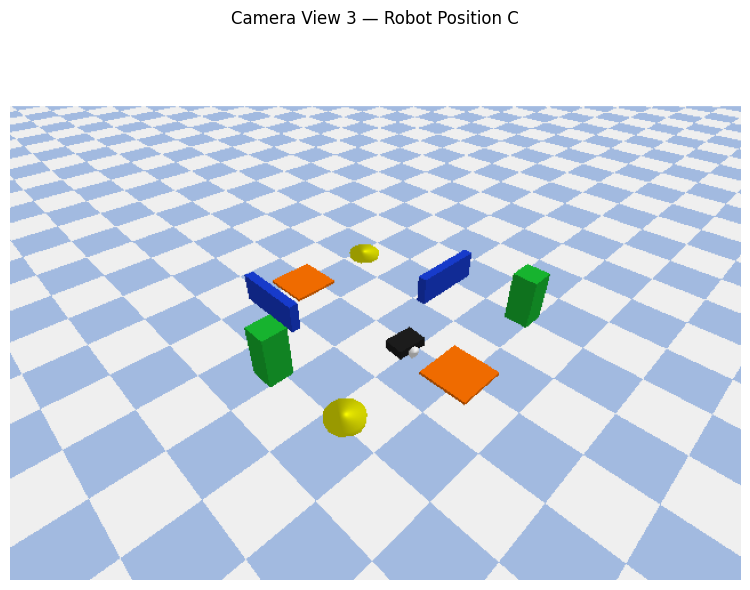

Saved: /content/rsp_task1_pybullet/outputs/camera_view_3.png


'/content/rsp_task1_pybullet/outputs/camera_view_3.png'

In [ ]:
pose_C = (0.2,0.9,0.16)
p.resetBasePositionAndOrientation(robot_id, pose_C, p.getQuaternionFromEuler([0,0,math.radians(175)]))
img3 = render_camera((4.7,4.8,5.5))
show_save(img3, "Camera View 3 — Robot Position C", "camera_view_3.png")

## 13. Three-view comparison

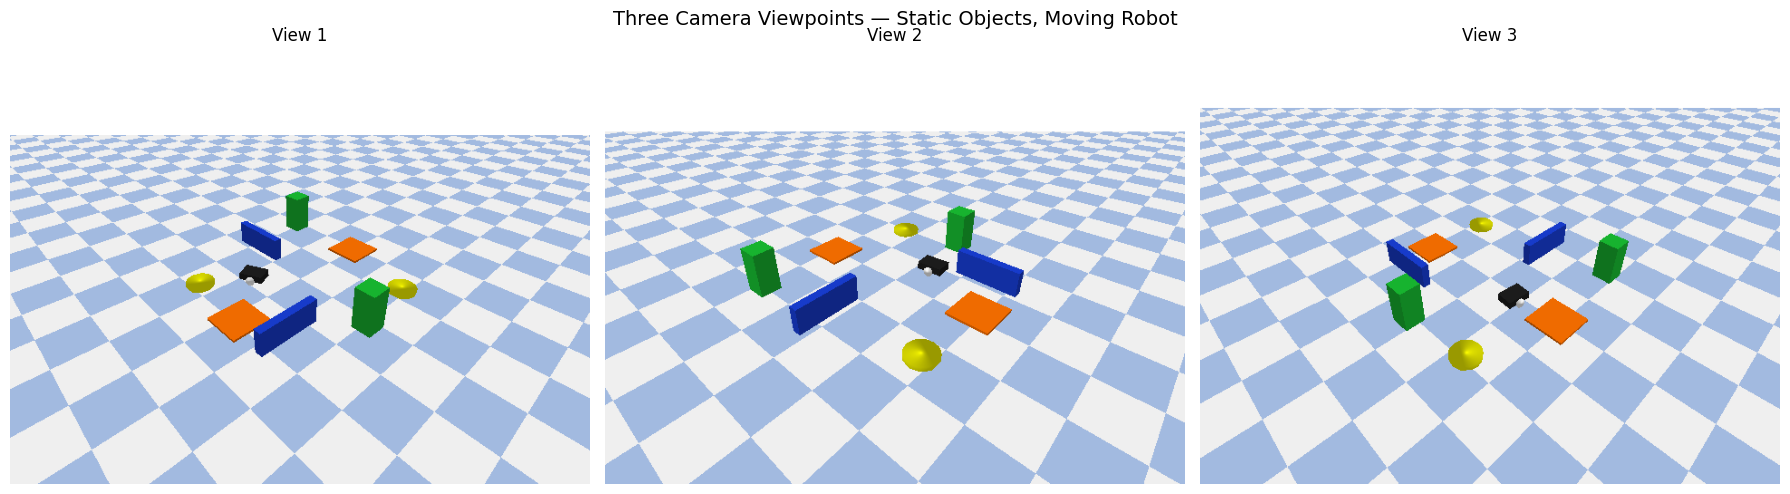

Saved: /content/rsp_task1_pybullet/outputs/three_camera_views.png


In [ ]:
fig, axes = plt.subplots(1,3,figsize=(18,5))
for ax, img, title in zip(axes,[img1,img2,img3],["View 1","View 2","View 3"]):
    ax.imshow(img)
    ax.set_title(title)
    ax.axis("off")
plt.suptitle("Three Camera Viewpoints — Static Objects, Moving Robot", fontsize=14)
plt.tight_layout()
comparison_path = os.path.join(OUTPUT_DIR, "three_camera_views.png")
plt.savefig(comparison_path, dpi=160, bbox_inches="tight")
plt.show()
print("Saved:", comparison_path)

## 14. Automated requirement checks

In [ ]:
static_ok = True
for body_id, original in static_positions.items():
    current, _ = p.getBasePositionAndOrientation(body_id)
    if not np.allclose(np.array(current), original, atol=1e-6):
        static_ok = False

categories = {meta["category"] for bid, meta in semantic_map.items() if bid != robot_id}
joint_names = [p.getJointInfo(robot_id,j)[1].decode() for j in range(p.getNumJoints(robot_id))]

checks = {
    "At least 4 semantic categories": len(categories) >= 4,
    "At least 8 static objects": len(scene_specs) >= 8,
    "Custom robot loaded": robot_id in semantic_map,
    "Left wheel exists": "left_wheel_joint" in joint_names,
    "Right wheel exists": "right_wheel_joint" in joint_names,
    "Static objects stayed fixed": static_ok,
    "Three camera images generated": all(x is not None for x in [img1,img2,img3]),
}
display(pd.DataFrame([{"Requirement":k,"Passed":v} for k,v in checks.items()]))

,Requirement,Passed
0,At least 4 semantic categories,True
1,At least 8 static objects,True
2,Custom robot loaded,True
3,Left wheel exists,True
4,Right wheel exists,True
5,Static objects stayed fixed,True
6,Three camera images generated,True


## 15. Save scene summary

In [ ]:
summary = {
    "scenario":"Autonomous Warehouse Inspection Robot",
    "mode":"PyBullet DIRECT",
    "static_object_count":len(scene_specs),
    "semantic_categories":sorted(list(categories)),
    "robot_name":semantic_map[robot_id]["name"],
    "robot_positions":{"view1":pose_A,"view2":pose_B,"view3":pose_C},
    "nearest_target":nearest_object("target"),
    "nearest_obstacle":nearest_object("obstacle")
}
with open(os.path.join(OUTPUT_DIR,"scene_summary.json"),"w") as f:
    json.dump(summary,f,indent=2)
print(json.dumps(summary,indent=2))

{
  "scenario": "Autonomous Warehouse Inspection Robot",
  "mode": "PyBullet DIRECT",
  "static_object_count": 8,
  "semantic_categories": [
    "landmark",
    "obstacle",
    "restricted_zone",
    "target"
  ],
  "robot_name": "Inspector_Robot",
  "robot_positions": {
    "view1": [
      -0.7,
      -0.8,
      0.16
    ],
    "view2": [
      0.8,
      -0.4,
      0.16
    ],
    "view3": [
      0.2,
      0.9,
      0.16
    ]
  },
  "nearest_target": {
    "body_id": 3,
    "name": "Target_A",
    "category": "target",
    "distance_m": 1.746,
    "position": [
      1.9,
      1.3,
      0.05
    ]
  },
  "nearest_obstacle": {
    "body_id": 1,
    "name": "Barrier_A",
    "category": "obstacle",
    "distance_m": 2.025,
    "position": [
      -1.7,
      0.2,
      0.275
    ]
  }
}


## 17. Package report evidence

In [ ]:
print("Output files:")
for f in sorted(os.listdir(OUTPUT_DIR)):
    print(" -", f)

zip_path = shutil.make_archive("/content/RSP_Task1_PyBullet_Evidence", "zip", OUTPUT_DIR)
print("\nEvidence ZIP:", zip_path)

Output files:
 - camera_view_1.png
 - camera_view_2.png
 - camera_view_3.png
 - scene_summary.json
 - three_camera_views.png

Evidence ZIP: /content/RSP_Task1_PyBullet_Evidence.zip
